# Weapon Detector - YOLOv5 Training (Google Colab, no API)
**Dataset:** `weapon-detection_v4i_yolov5pytorch.zip` (classes: Handgun, Knife, Rifle, Sword)

**Before starting:** Runtime > Change runtime type > **T4 GPU**, then run the cells in order.

## 1. Check GPU

In [1]:
!nvidia-smi

Mon Oct 19 20:20:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install YOLOv5

In [2]:
!git clone https://github.com/ultralytics/yolov5 /content/yolov5
%cd /content/yolov5
!pip install -r requirements.txt -q
import torch
print('Torch:', torch.__version__, '| GPU available:', torch.cuda.is_available())

Cloning into '/content/yolov5'...
remote: Enumerating objects: 18796, done.
remote: Counting objects: 100% (367/367), done.
remote: Compressing objects: 100% (214/214), done.
remote: Total 18796 (delta 305), reused 153 (delta 153), pack-reused 18429 (from 2)
Receiving objects: 100% (18796/18796), 17.71 MiB | 19.29 MiB/s, done.
Resolving deltas: 100% (12808/12808), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.6 MB/s eta 0:00:00
Torch: 2.11.0+cu130 | GPU available: True


## 3. Upload your dataset zip
A file picker will appear. Choose `weapon-detection_v4i_yolov5pytorch.zip` and wait for the upload to reach 100%.

In [4]:
import os, glob
from google.colab import files

uploaded = files.upload()
zipname = list(uploaded.keys())[0]
print('Uploaded:', zipname)

!rm -rf /content/raw
!mkdir -p /content/raw
!unzip -q -o "{zipname}" -d /content/raw

RAW = os.path.dirname(glob.glob('/content/raw/**/data.yaml', recursive=True)[0])
print('Dataset folder:', RAW)
print('Train images:', len(os.listdir(f'{RAW}/train/images')))
print('Valid folder exists:', os.path.isdir(f'{RAW}/valid'))
print('Test folder exists:', os.path.isdir(f'{RAW}/test'))

Saving weapon-detection.v4i.yolov5pytorch.zip to weapon-detection.v4i.yolov5pytorch.zip
Uploaded: weapon-detection.v4i.yolov5pytorch.zip
Dataset folder: /content/raw
Train images: 1863
Valid folder exists: False
Test folder exists: False


## 4. Clean labels and create train / val / test split
This zip only has a `train` folder, so the notebook splits it **80% train / 10% val / 10% test**. It also removes malformed label lines (one polygon-style line exists in this dataset) and writes a fresh `data.yaml`.

In [5]:
import random, shutil, yaml
from pathlib import Path

random.seed(42)
SRC_IMG = Path(RAW) / 'train' / 'images'
SRC_LBL = Path(RAW) / 'train' / 'labels'
OUT = Path('/content/weapon_data')
shutil.rmtree(OUT, ignore_errors=True)

with open(f'{RAW}/data.yaml') as f:
    names = yaml.safe_load(f)['names']
print('Classes:', names)

images = sorted([p for p in SRC_IMG.iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}])
random.shuffle(images)
n = len(images)
n_train, n_val = int(n * 0.8), int(n * 0.1)
splits = {
    'train': images[:n_train],
    'val': images[n_train:n_train + n_val],
    'test': images[n_train + n_val:],
}

fixed_lines = 0
for split, items in splits.items():
    (OUT / split / 'images').mkdir(parents=True)
    (OUT / split / 'labels').mkdir(parents=True)
    for img in items:
        shutil.copy(img, OUT / split / 'images' / img.name)
        lbl = SRC_LBL / (img.stem + '.txt')
        clean = []
        if lbl.exists():
            for line in lbl.read_text().strip().splitlines():
                parts = line.split()
                if len(parts) == 5:          # valid YOLO box: class x y w h
                    clean.append(line.strip())
                else:
                    fixed_lines += 1
        (OUT / split / 'labels' / (img.stem + '.txt')).write_text('\n'.join(clean) + ('\n' if clean else ''))
    print(split, '->', len(items), 'images')

print('Removed malformed label lines:', fixed_lines)

DATA_YAML = str(OUT / 'data.yaml')
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump({
        'path': str(OUT),
        'train': 'train/images',
        'val': 'val/images',
        'test': 'test/images',
        'nc': len(names),
        'names': names,
    }, f, sort_keys=False)
print(open(DATA_YAML).read())

Classes: ['Handgun', 'Knife', 'Rifle', 'Sword']
train -> 1490 images
val -> 186 images
test -> 187 images
Removed malformed label lines: 1
path: /content/weapon_data
train: train/images
val: val/images
test: test/images
nc: 4
names:
- Handgun
- Knife
- Rifle
- Sword



## 5. Train
Starts from pretrained `yolov5s.pt`. About 80 epochs; early stopping triggers if there is no improvement for 20 epochs. If you get a CUDA out-of-memory error, change `--batch 16` to `--batch 8`.

In [6]:
%cd /content/yolov5
!python train.py --img 640 --batch 16 --epochs 80 --data {DATA_YAML} --weights yolov5s.pt --name weapon_det --cache --patience 20

/content/yolov5
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1792441818.990206    5216 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/weapon_data/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=80, batc

## 6. View training results

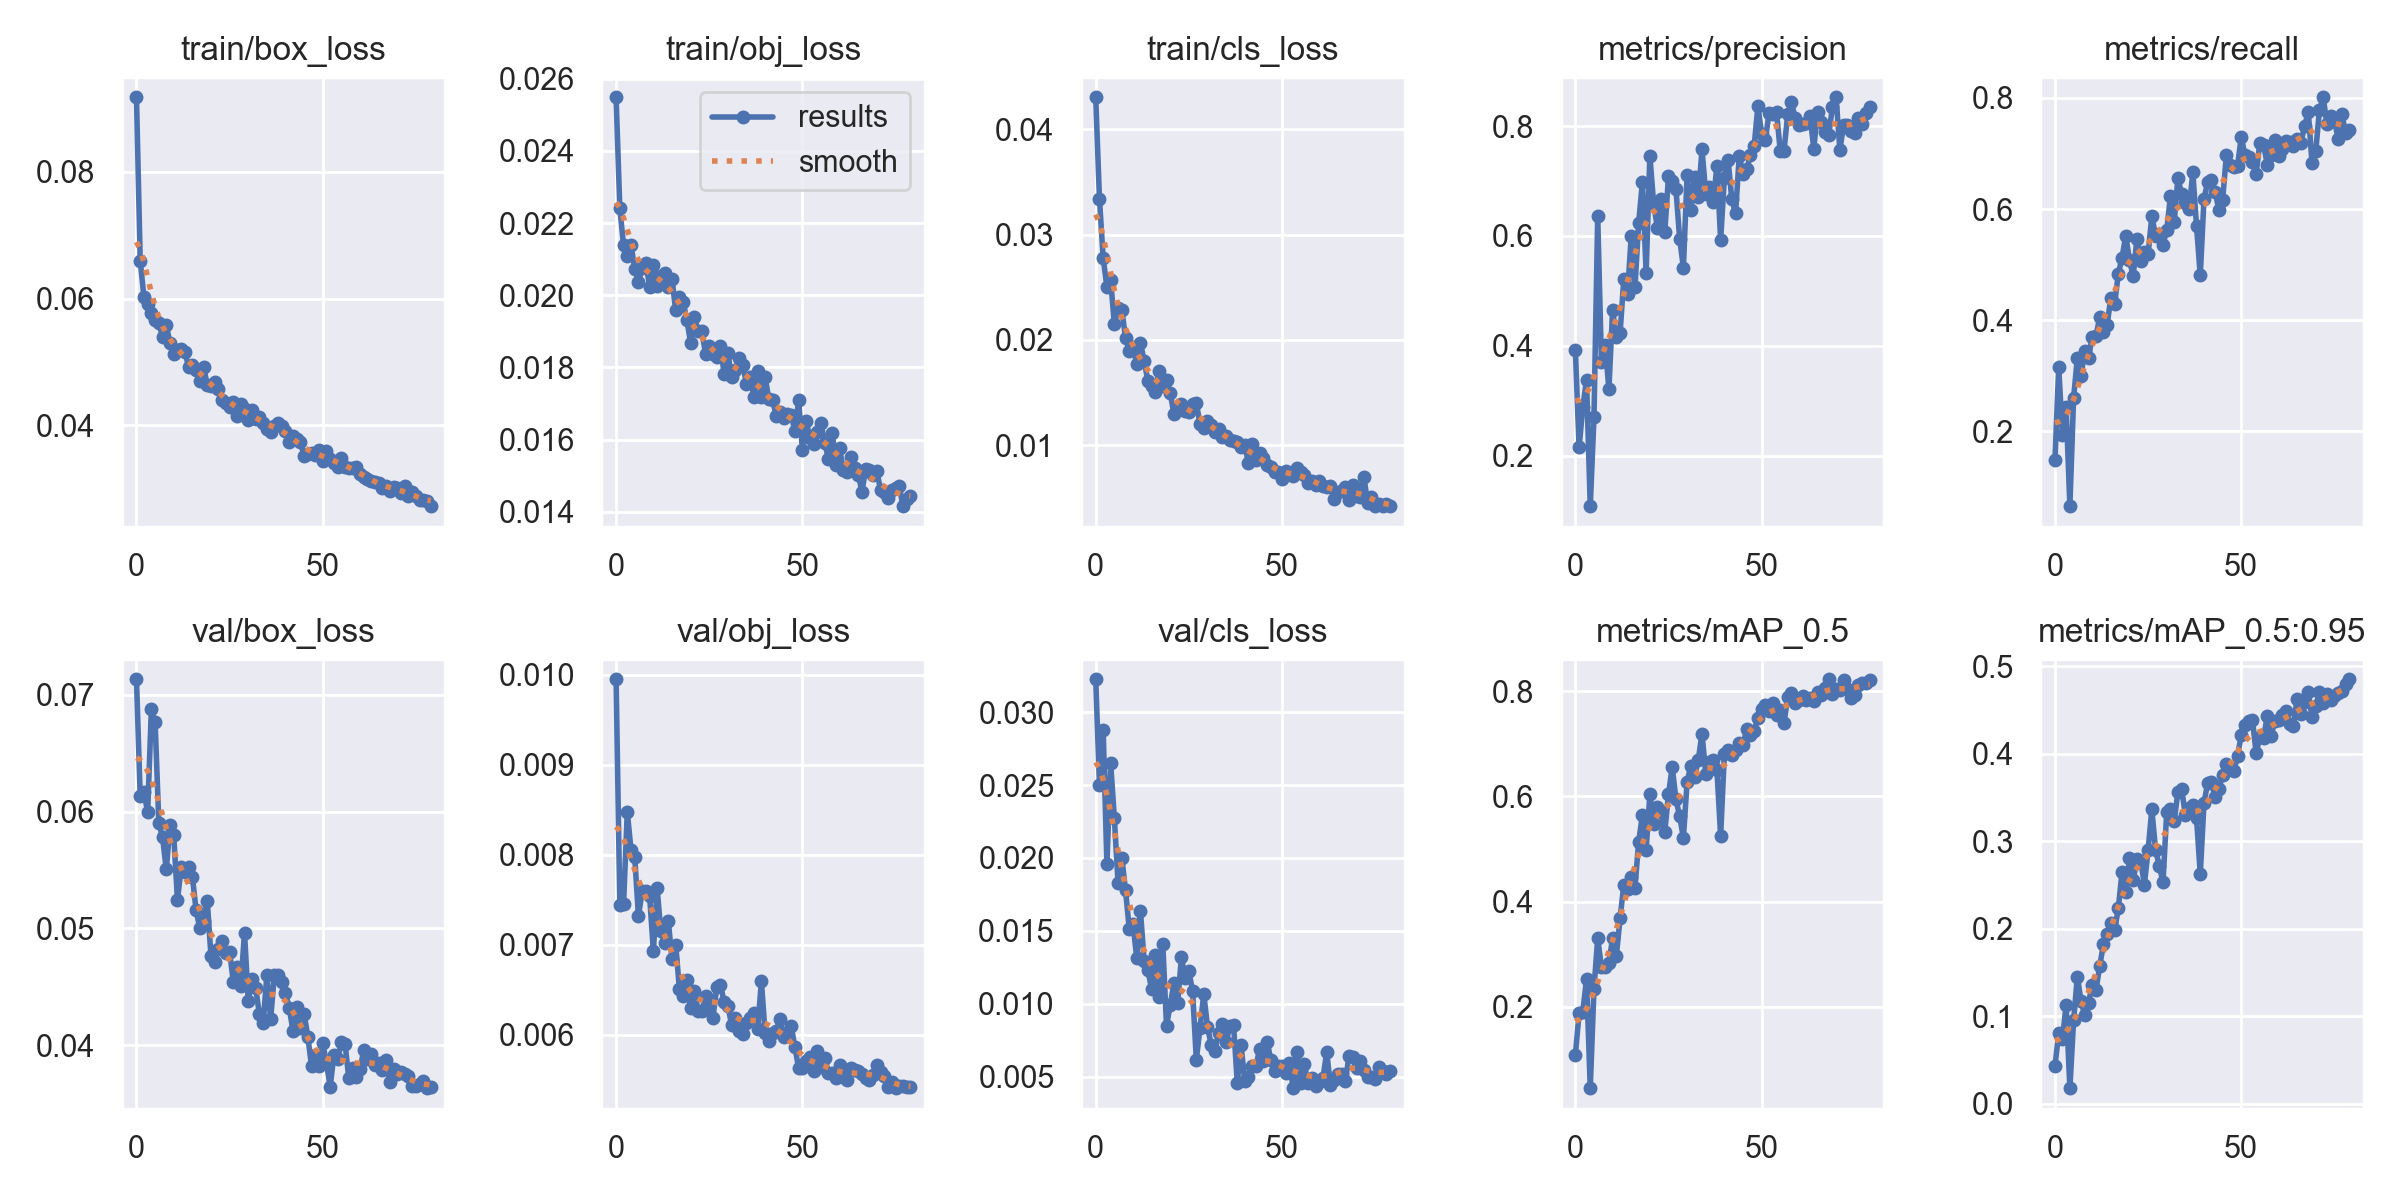

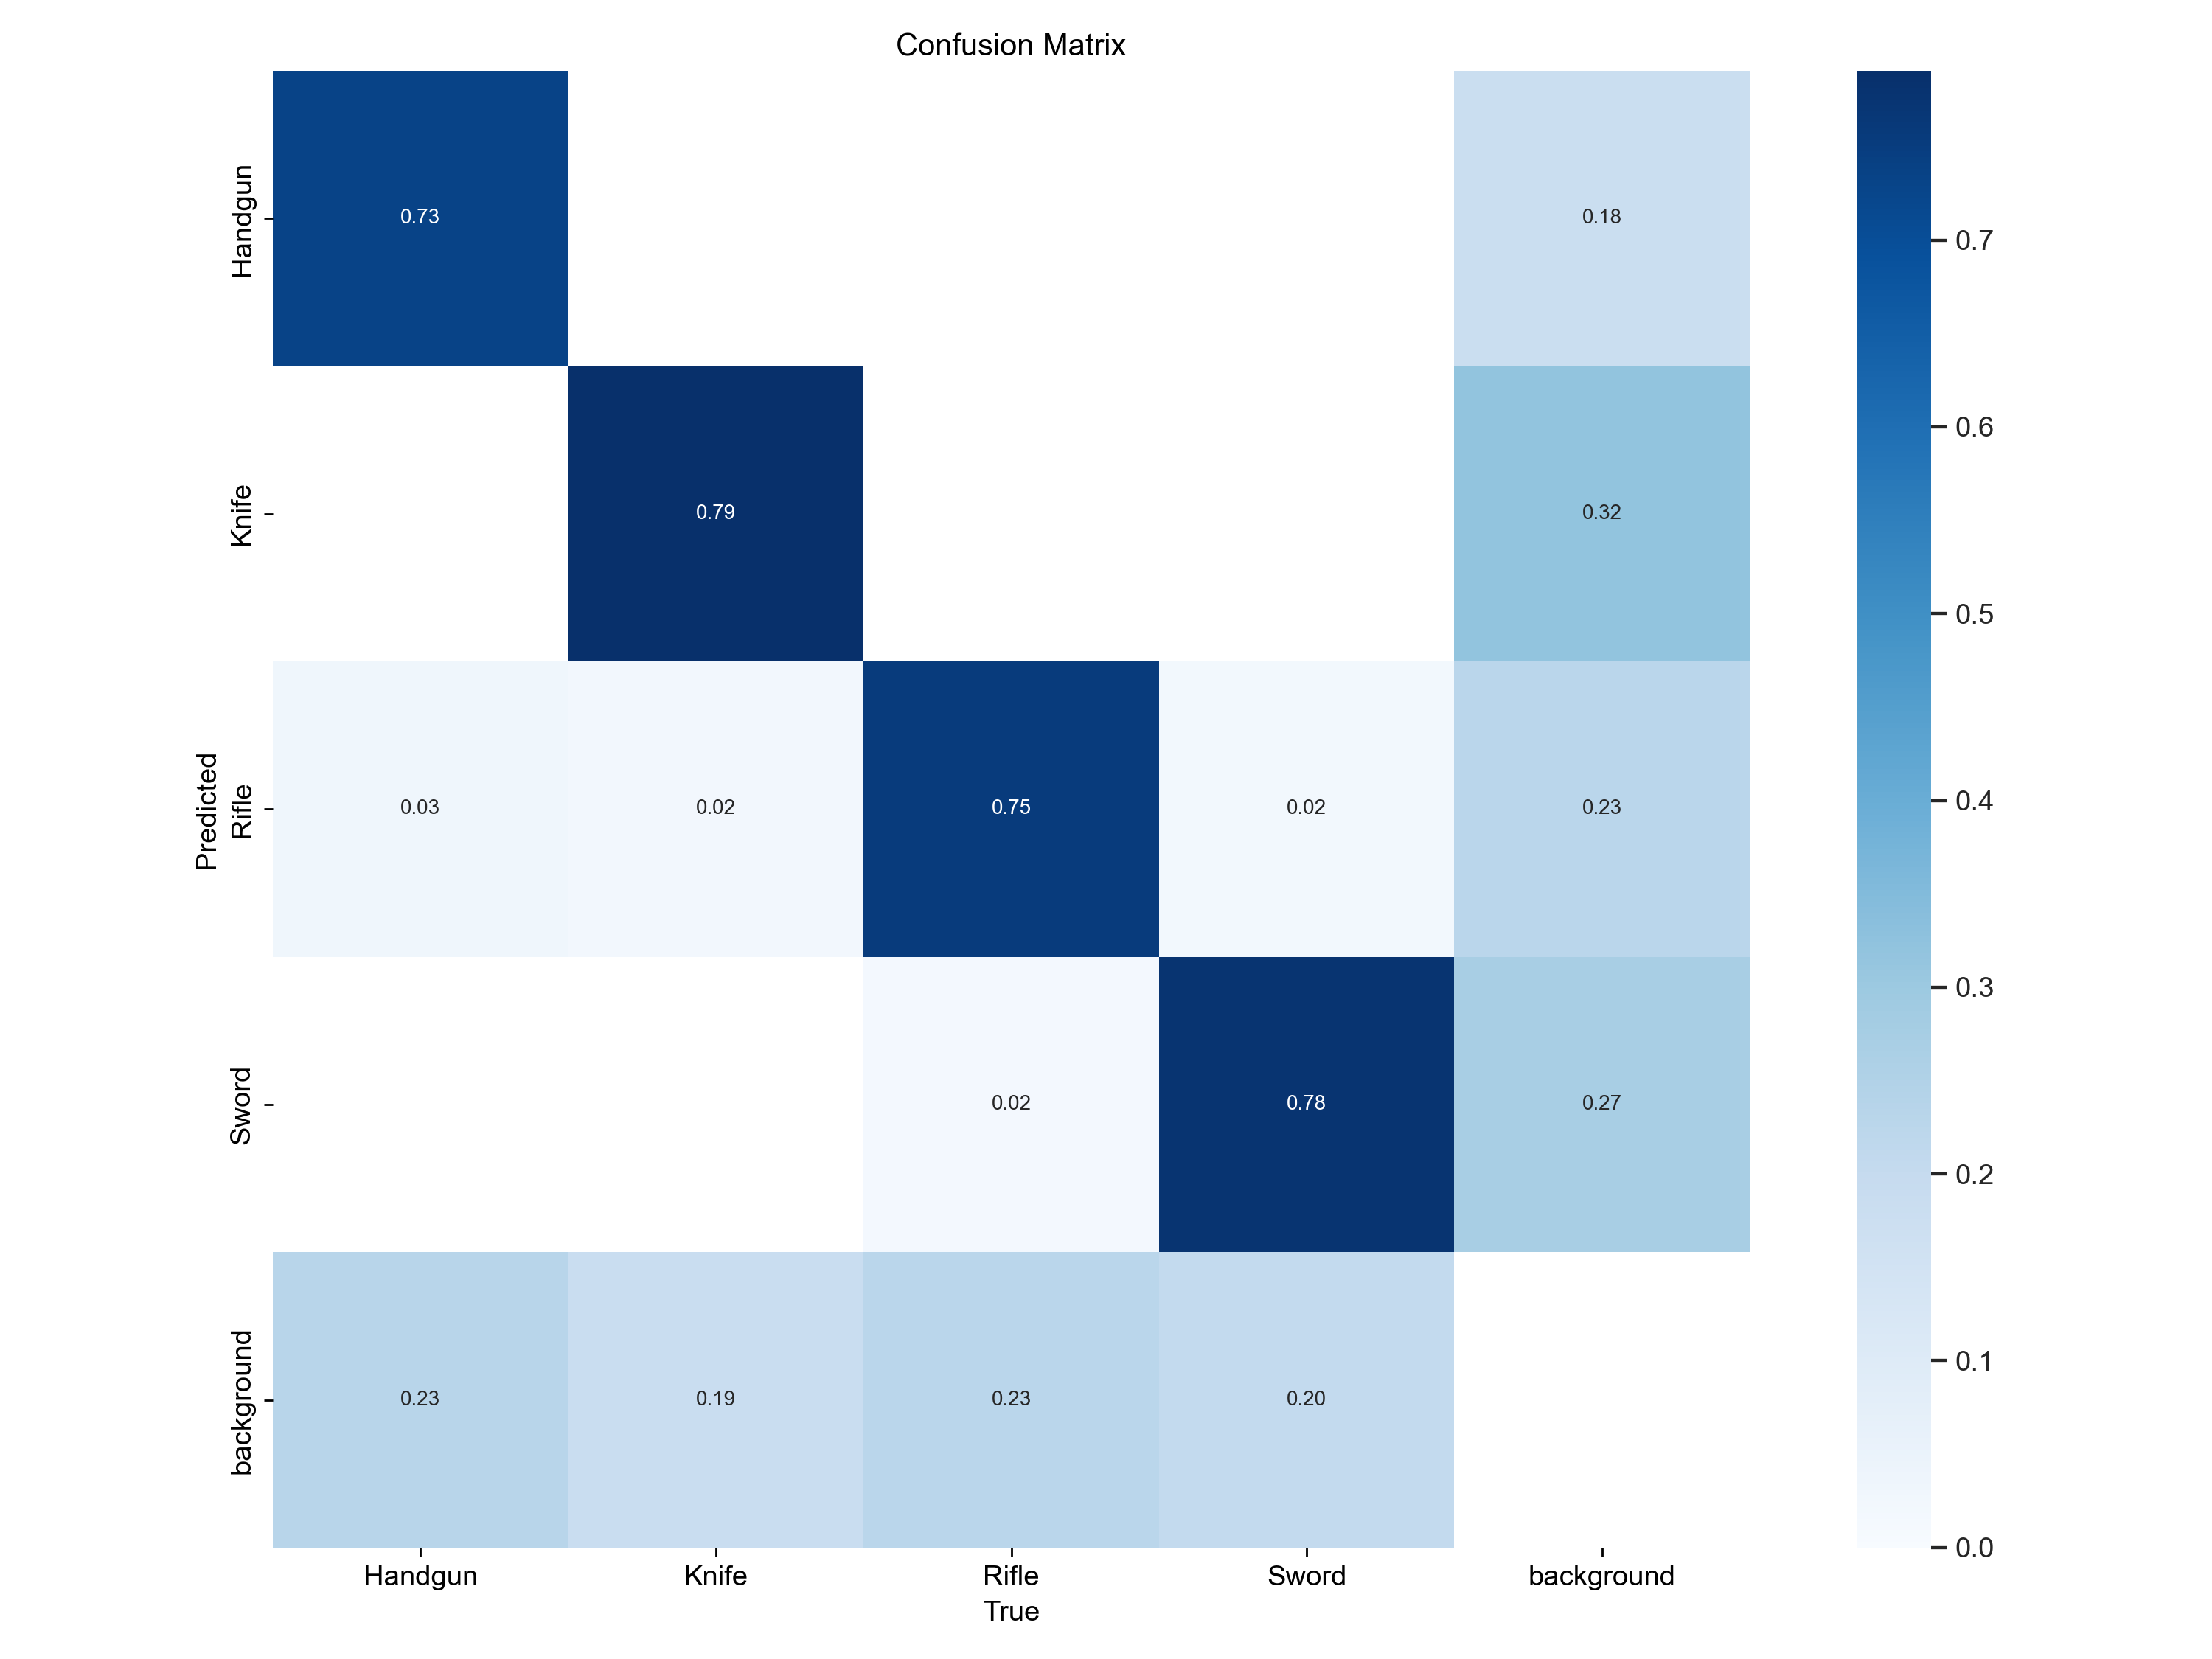

In [7]:
from IPython.display import Image, display
display(Image('/content/yolov5/runs/train/weapon_det/results.png'))
display(Image('/content/yolov5/runs/train/weapon_det/confusion_matrix.png'))

## 7. Evaluate on the unseen test split
Look at precision (P), recall (R) and mAP@0.5 for each class.

In [8]:
%cd /content/yolov5
!python val.py --weights runs/train/weapon_det/weights/best.pt --data {DATA_YAML} --img 640 --task test --name weapon_test

/content/yolov5
val: data=/content/weapon_data/data.yaml, weights=['runs/train/weapon_det/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=weapon_test, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-559-g908fedf4 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,020,913 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/weapon_data/test/labels... 187 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 187/187 601.4it/s 0.3s
test: New cache created: /content/weapon_data/test/labels.cache
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 6/6 1.3it/s 4.6s
                   all        187        204      0.827      0.757      0.801      0.492
       

## 8. Test with your own images (upload)
Choose any images and the detections will be shown below.

Saving OIP.jpg to OIP.jpg
/content/yolov5
detect: weights=['runs/train/weapon_det/weights/best.pt'], source=/content/test_images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.4, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=my_test, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-559-g908fedf4 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,020,913 parameters, 0 gradients, 15.8 GFLOPs
image 1/1 /content/test_images/OIP.jpg: 448x640 1 Handgun, 28.1ms
Speed: 0.5ms pre-process, 28.1ms inference, 111.6ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/my_test


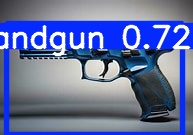

In [9]:
import os, glob, shutil
from google.colab import files
from IPython.display import Image, display

shutil.rmtree('/content/test_images', ignore_errors=True)
os.makedirs('/content/test_images')
up = files.upload()
for name in up:
    shutil.move(name, f'/content/test_images/{name}')

%cd /content/yolov5
!rm -rf runs/detect/my_test
!python detect.py --weights runs/train/weapon_det/weights/best.pt --img 640 --conf 0.4 --source /content/test_images --name my_test
for f in sorted(glob.glob('runs/detect/my_test/*')):
    display(Image(f))

## 9. Download your trained model
This downloads `best.pt` to your PC. Put it in your VS Code project folder next to `detect.py`.

In [10]:
from google.colab import files
files.download('/content/yolov5/runs/train/weapon_det/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Optional: backup to Google Drive
Run this if you want a copy of the model in your Drive.